# Genotype prediction: deletions and insertions together

The other pipeline notebooks predict a coarse class. This one predicts the
**genotype**, the actual sequence inserted or deleted, with deletions and
insertions sharing one label space.

That is how the published models are framed. Lindel uses 557 classes (Chen et
al., 2019) and FORECasT around a thousand (Allen et al., 2019). Here every
genotype up to 3 bases is its own class, and longer events fall into
`del_large` or `ins_large`.

**The data is synthetic** and the informative positions are known, so
attribution can be scored. **No biological claim is made here.**

**The rule.** Length and content come from different places. Which bases are
deleted is not a choice, it is whatever sits at the cut. How many are deleted
depends on wider context.

- Deletion: length from a three base block 5' of the cut, content from the
  bases at the cut.
- Insertion: length from a three base block 3' of the cut, content a copy of
  the bases just 5' of the cut (van Overbeek et al., 2016).

So the model reads two regions and combines them into one label. Right length
with wrong content still scores zero.

**Evaluation changes at this scale.**

- **Top k accuracy**, because one genotype out of 171 is a hard argmax.
- **The baseline is a frequency prior, not a majority class.** Predicting the
  overall genotype frequencies uses no sequence at all. Beating it on the site
  level correlation is the test of whether sequence is being used. That is
  section 8.

## 1. Setup

In [1]:
import sys, subprocess
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT))
import crispr_attention as ca

DOCS, MODELS, EXAMPLES = ROOT / "docs", ROOT / "models", ROOT / "examples"
for d in (DOCS, MODELS, EXAMPLES):
    d.mkdir(exist_ok=True)

SEED = 0
torch.manual_seed(SEED)
np.random.seed(SEED)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight",
                     "font.size": 9, "axes.spines.top": False, "axes.spines.right": False})

def savefig(fig, name):
    fig.savefig(DOCS / (name + ".png"))
    return fig

print("python", sys.version.split()[0], "| torch", torch.__version__, "| device", DEVICE)

python 3.12.3 | torch 2.14.1+cu130 | device cpu


## 2. The data and its vocabulary

One group is one target site. The class vocabulary is built from the genotypes
that actually occur, ordered as `no_indel`, then deletions, then insertions,
then the two large bins.

In [2]:
X, y, groups, CLASSES, cut = ca.make_genotype_task(
    n_groups=5000, per_group=10, length=40,
    cut=20, max_unit=3, seed=SEED)

WINDOW = (cut - 2 * 3, cut + 2 * 3)   # known informative span

n_del = sum(c.startswith("del_") and c != "del_large" for c in CLASSES)
n_ins = sum(c.startswith("ins_") and c != "ins_large" for c in CLASSES)

print("reads       ", format(len(X), ","))
print("target sites", format(len(np.unique(groups)), ","))
print("classes     ", len(CLASSES),
      f"({n_del} deletion genotypes, {n_ins} insertion genotypes, 2 large bins, 1 no_indel)")
print("informative  positions", WINDOW[0], "to", WINDOW[1] - 1)
print()
print("example classes:", CLASSES[:3], "...", CLASSES[-4:])
print("example read   :", ca.decode(X[0]), "->", CLASSES[y[0]])

reads        50,000
target sites 5,000
classes      171 (84 deletion genotypes, 84 insertion genotypes, 2 large bins, 1 no_indel)
informative  positions 14 to 25

example classes: ['no_indel', 'del_A', 'del_AA'] ... ['ins_TTG', 'ins_TTT', 'del_large', 'ins_large']
example read   : TGGCCAAACAAAAGGGCGTCCTTTCGTGTGGCATAGACCC -> no_indel


most common genotype : no_indel  (16,067 reads)
rarest genotype      : ins_CGC  (52 reads)
median reads a class : 127
head of the tail     : the top 5 classes hold 46.2% of all reads


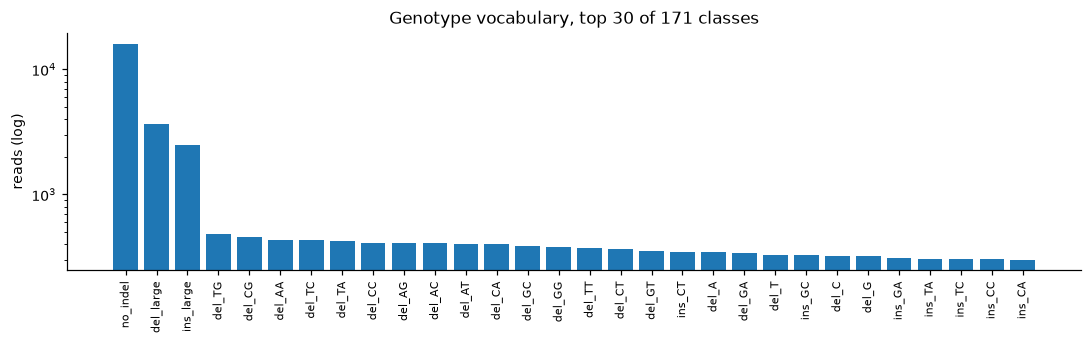

In [3]:
savefig(ca.plots.genotype_vocabulary(y, CLASSES, top_n=30), "geno_vocabulary")

counts = np.bincount(y, minlength=len(CLASSES))
print(f"most common genotype : {CLASSES[counts.argmax()]}  ({counts.max():,} reads)")
print(f"rarest genotype      : {CLASSES[np.argmin(np.where(counts > 0, counts, 10**9))]}"
      f"  ({counts[counts > 0].min():,} reads)")
print(f"median reads a class : {int(np.median(counts[counts > 0])):,}")
print(f"head of the tail     : the top 5 classes hold "
      f"{np.sort(counts)[-5:].sum() / counts.sum():.1%} of all reads")

### Three reference points, not one

`bayes_ceiling` is still the most any per read classifier can reach, because
reads at a site share a sequence but not an outcome. The majority baseline is
reported for continuity with the other notebooks, but the **frequency prior**
is the one that matters here, and it is evaluated properly in section 7.

In [4]:
baseline = counts.max() / len(y)
ceiling = ca.bayes_ceiling(y, groups)
print(f"majority class baseline : {baseline:.4f}  ('{CLASSES[counts.argmax()]}')")
print(f"group ceiling           : {ceiling:.4f}")
print(f"headroom available      : {ceiling - baseline:.4f}")

majority class baseline : 0.3213  ('no_indel')
group ceiling           : 0.5310
headroom available      : 0.2097


## 3. Split by target site

In [5]:
train, val, test = ca.group_split(groups, train=0.7, val=0.15, seed=SEED)
gtr, gva, gte = (set(groups[i]) for i in (train, val, test))
assert not (gtr & gva) and not (gtr & gte) and not (gva & gte)

seen = {X[i].tobytes() for i in train}
display(pd.DataFrame({"split": ["train", "validation", "test"],
                      "sites": [len(gtr), len(gva), len(gte)],
                      "reads": [len(train), len(val), len(test)]}))
print("no site appears in two splits: OK")
print(f"test reads whose exact sequence also appears in train: "
      f"{np.mean([X[i].tobytes() in seen for i in test]):.1%}")
print(f"classes present in training: {len(np.unique(y[train]))} of {len(CLASSES)}")

,split,sites,reads
0,train,3500,35000
1,validation,750,7500
2,test,750,7500


no site appears in two splits: OK
test reads whose exact sequence also appears in train: 0.0%
classes present in training: 171 of 171


## 4. The model

The same architecture as the other two notebooks, with a wider recurrent layer
because the output space is far larger. The parameter count is still small.
Note what the output layer costs: one row per genotype.

In [6]:
model = ca.AttentionBiLSTM(num_classes=len(CLASSES), embed_dim=32, hidden_dim=96,
                           attn_dim=96, dropout=0.3, use_positional=True)
print("trainable parameters:", format(model.n_parameters(), ","))
print("output layer alone  :", format(192 * len(CLASSES) + len(CLASSES), ","),
      f"({len(CLASSES)} classes)")
print("training sites      :", format(len(gtr), ","))
print("training reads      :", format(len(train), ","))

trainable parameters: 151,660
output layer alone  : 33,003 (171 classes)
training sites      : 3,500
training reads      : 35,000


## 5. Training, **without** class weighting

The other two notebooks use class weighted loss, the usual answer to
imbalance. This one does not, and that is deliberate. Section 9 trains the
weighted model on the same data and shows what the weighting does.

The short version: the target here is a **distribution over genotypes**. Class
weighting works by pushing predicted probabilities away from the observed
frequencies. When the frequencies are what you are estimating, that is damage.

In [7]:
model, history = ca.fit(model, X[train], y[train], X[val], y[val],
                        epochs=20, patience=5, batch_size=128, lr=1e-3,
                        weight_decay=1e-4, class_weight=False,
                        device=DEVICE, verbose=True)

epoch   1  train loss 3.8325  val loss 3.6286  val macro F1 0.0051


epoch   2  train loss 3.1165  val loss 2.6949  val macro F1 0.0151


epoch   3  train loss 2.3603  val loss 2.1485  val macro F1 0.1189


epoch   4  train loss 1.9541  val loss 1.8231  val macro F1 0.1325


epoch   5  train loss 1.7631  val loss 1.6555  val macro F1 0.1570


...

epoch  10  train loss 1.3874  val loss 1.3144  val macro F1 0.2073


epoch  11  train loss 1.3624  val loss 1.3065  val macro F1 0.2236


epoch  12  train loss 1.3494  val loss 1.2852  val macro F1 0.2106


epoch  13  train loss 1.3382  val loss 1.2937  val macro F1 0.2109


epoch  14  train loss 1.3258  val loss 1.2955  val macro F1 0.1749
early stopping at epoch 14, best val macro F1 0.2334


best epoch 9 of 14, validation macro F1 0.2334


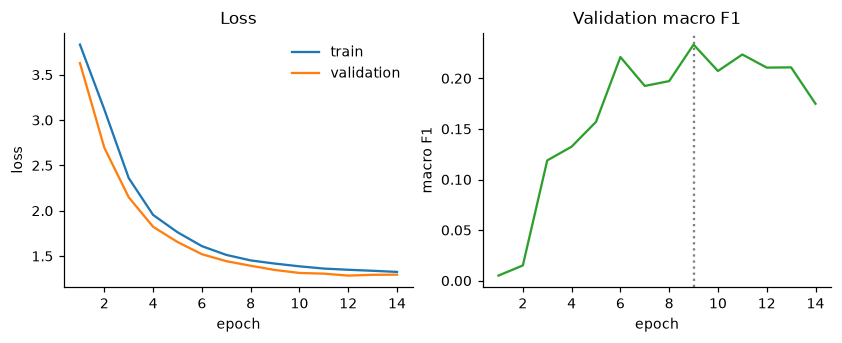

In [8]:
h = pd.DataFrame(history)
fig, ax = plt.subplots(1, 2, figsize=(9, 3))
ax[0].plot(h.epoch, h.train_loss, label="train")
ax[0].plot(h.epoch, h.val_loss, label="validation")
ax[0].set(xlabel="epoch", ylabel="loss", title="Loss")
ax[0].legend(frameon=False)
best = int(h.val_macro_f1.idxmax()) + 1
ax[1].plot(h.epoch, h.val_macro_f1, color="tab:green")
ax[1].axvline(best, ls=":", color="grey")
ax[1].set(xlabel="epoch", ylabel="macro F1", title="Validation macro F1")
savefig(fig, "geno_training_curves")
print(f"best epoch {best} of {len(h)}, validation macro F1 {h.val_macro_f1.max():.4f}")

## 6. Read level evaluation, with top k

Getting one genotype out of a few hundred exactly right is a hard ask, so the
ranking matters as much as the argmax.

In [9]:
proba = ca.predict_proba(model, X[test], device=DEVICE)
pred = proba.argmax(1)
res = ca.evaluate(y[test], pred, y_train=y[train], target_names=CLASSES)
topk = ca.topk_accuracy(y[test], proba, ks=(1, 3, 5, 10, 20))

print(f"classes                 : {len(CLASSES)}")
print(f"majority class baseline : {res['baseline']['accuracy']:.4f}")
print(f"group ceiling           : {ceiling:.4f}")
print()
for k, v in topk.items():
    print(f"top {k:<3} accuracy        : {v:.4f}")
print()
print(f"macro F1                : {res['macro_f1']:.4f} "
      f"(baseline {res['baseline']['macro_f1']:.4f})")
print(f"balanced accuracy       : {res['balanced_accuracy']:.4f}")

classes                 : 171
majority class baseline : 0.3144
group ceiling           : 0.5310

top 1   accuracy        : 0.4251
top 3   accuracy        : 0.9779
top 5   accuracy        : 0.9957
top 10  accuracy        : 0.9997
top 20  accuracy        : 1.0000

macro F1                : 0.2303 (baseline 0.0029)
balanced accuracy       : 0.2898


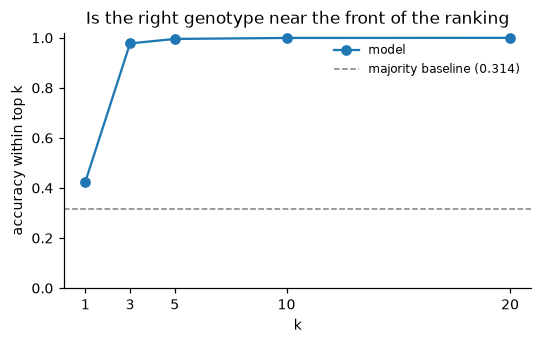

In [10]:
savefig(ca.plots.topk_curve(topk, baseline_top1=res["baseline"]["accuracy"]),
        "geno_topk_curve");

## 7. Where the errors go

A confusion matrix over every genotype would be unreadable, so the classes are
collapsed into the event they represent. This answers a different and more
useful question: does the model get the **kind** of event right even when it
misses the exact sequence?

exact genotype correct        : 0.4251
event type correct            : 0.4251
right event, wrong sequence   : 0.0000

Those first two numbers are the same, and that is the finding.
Whenever the model picks the right event type it also picks the exact
sequence, so content is never the failure mode. This follows from the
generating rule: a site has one deletion genotype and one insertion
genotype, so once the event and its length are right, which bases are
involved is already determined. The model's errors are therefore errors
about WHICH event occurred, not about which bases it moved.


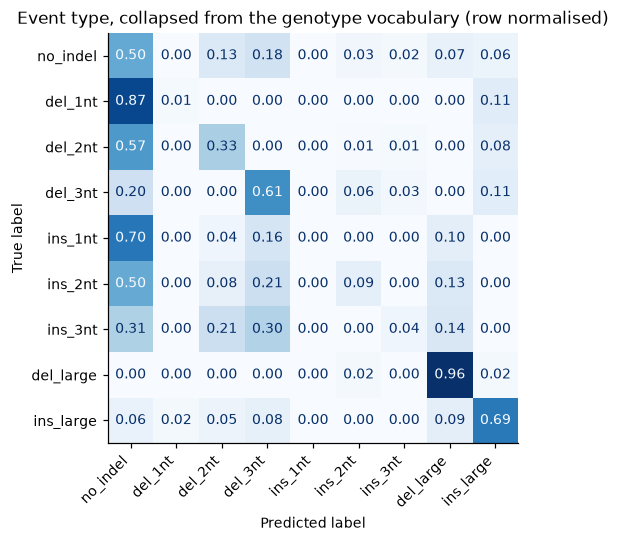

In [11]:
def event_group(name):
    if name == "no_indel":
        return "no_indel"
    kind = name[:3]
    if name.endswith("large"):
        return f"{kind}_large"
    return f"{kind}_{len(name) - 4}nt"

GROUPS = ["no_indel"] + [f"{k}_{n}nt" for k in ("del", "ins") for n in (1, 2, 3)] \
         + ["del_large", "ins_large"]
gidx = {g: i for i, g in enumerate(GROUPS)}
to_group = np.array([gidx[event_group(c)] for c in CLASSES])

from sklearn.metrics import confusion_matrix
cm = confusion_matrix(to_group[y[test]], to_group[pred], labels=range(len(GROUPS)))
savefig(ca.plots.confusion(cm, GROUPS, normalise=True,
                           title="Event type, collapsed from the genotype vocabulary"),
        "geno_confusion_event")

exact = (pred == y[test]).mean()
same_event = (to_group[pred] == to_group[y[test]]).mean()
right_event_wrong_seq = ((to_group[pred] == to_group[y[test]]) & (pred != y[test])).mean()

print(f"exact genotype correct        : {exact:.4f}")
print(f"event type correct            : {same_event:.4f}")
print(f"right event, wrong sequence   : {right_event_wrong_seq:.4f}")
print()
if right_event_wrong_seq < 0.01:
    print("Those first two numbers are the same, and that is the finding.")
    print("Whenever the model picks the right event type it also picks the exact")
    print("sequence, so content is never the failure mode. This follows from the")
    print("generating rule: a site has one deletion genotype and one insertion")
    print("genotype, so once the event and its length are right, which bases are")
    print("involved is already determined. The model's errors are therefore errors")
    print("about WHICH event occurred, not about which bases it moved.")
else:
    print("The gap between the two is the model getting the event right while")
    print("missing the exact sequence, so content is a real failure mode here.")

### Precision and recall for the head of the vocabulary

Shown for the eight most common genotypes. Each is scored against its own
prevalence, which for a class holding under 1% of reads is a demanding
comparison.

In [12]:
top8 = np.argsort(-counts)[:8]
fig, rows = ca.plots.pr_curves(y[test], proba, CLASSES)
plt.close(fig)
ap = pd.DataFrame(rows)
ap = ap[ap["class"].isin([CLASSES[i] for i in top8])].sort_values("average_precision",
                                                                 ascending=False)
display(ap.round(4))

/home/claude/repo/crispr_attention/plots.py:51: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  fig.tight_layout()


,class,n_positive,average_precision,chance,lift
165,del_large,613,0.5676,0.0817,6.9450
62,del_TA,83,0.5154,0.0111,46.5710
31,del_CG,93,0.4734,0.0124,38.1768
72,del_TG,66,0.4512,0.0088,51.2682
67,del_TC,101,0.4420,0.0135,32.8196
0,no_indel,2358,0.4235,0.3144,1.3469
166,ins_large,328,0.3746,0.0437,8.5651
2,del_AA,51,0.3148,0.0068,46.2882


## 8. The comparison that decides it: site level, against the frequency prior

This is the section that matters. Predicting the overall genotype frequencies
for every site requires no sequence information at all, and because the
vocabulary is long tailed that null model already scores respectably on
anything averaged over classes.

A sequence model has to beat it on the **site level correlation**. If it does
not, it has learned which genotypes are common, not which genotypes a given
site produces.

In [13]:
site = ca.site_evaluate(proba, y[test], groups[test], n_classes=len(CLASSES))
prior = ca.prior_baseline(y[train], y[test], groups[test], n_classes=len(CLASSES))

comparison = pd.DataFrame({
    "metric": ["site pooled Pearson r", "site modal accuracy",
               "site mean absolute error", "read top 1 accuracy"],
    "frequency prior (no sequence)": [
        round(prior["site_pooled_pearson_r"], 4),
        round(prior["site_modal_accuracy"], 4),
        round(prior["site_mean_absolute_error"], 4),
        round(prior["accuracy"], 4)],
    "sequence model": [
        round(site["pooled_pearson_r"], 4),
        round(site["modal_accuracy"], 4),
        round(site["mean_absolute_error"], 4),
        round(topk[1], 4)],
})
display(comparison)

gain_r = site["pooled_pearson_r"] - prior["site_pooled_pearson_r"]
gain_mae = prior["site_mean_absolute_error"] - site["mean_absolute_error"]
print(f"correlation gained over the prior : {gain_r:+.4f}")
print(f"absolute error removed            : {gain_mae:+.4f}"
      f"  ({gain_mae / max(prior['site_mean_absolute_error'], 1e-9):+.1%})")
print()
if gain_r > 0.05 and gain_mae > 0:
    print("The model is using sequence. It predicts which genotypes a given site")
    print("produces, not merely which genotypes are common overall. This is the")
    print("claim the notebook is making, and this table is the evidence for it.")
else:
    print("The model is NOT clearly beating the frequency prior. On this evidence it")
    print("has learned the vocabulary rather than the sequence dependence, and the")
    print("read level accuracy should not be quoted as if it had.")

,metric,frequency prior (no sequence),sequence model
0,site pooled Pearson r,0.4960,0.8623
1,site modal accuracy,0.3440,0.5320
2,site mean absolute error,0.0086,0.0035
3,read top 1 accuracy,0.3144,0.4251


correlation gained over the prior : +0.3663
absolute error removed            : +0.0050  (+58.6%)

The model is using sequence. It predicts which genotypes a given site
produces, not merely which genotypes are common overall. This is the
claim the notebook is making, and this table is the evidence for it.


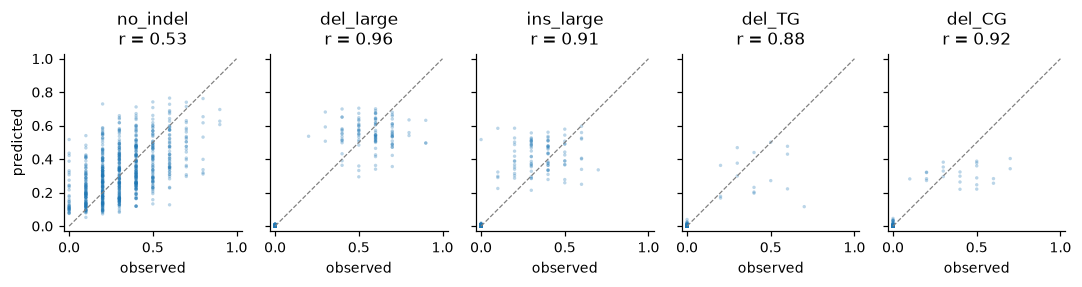

In [14]:
savefig(ca.plots.predicted_vs_observed(site["predicted"][:, np.argsort(-counts)[:5]],
                                       site["observed"][:, np.argsort(-counts)[:5]],
                                       [CLASSES[i] for i in np.argsort(-counts)[:5]]),
        "geno_site_predicted_vs_observed");

## 9. Why class weighting is the wrong reflex for this task

Imbalanced classes usually call for class weighted loss, and the other two
notebooks in this repository use it. Here it hurts. The cell below trains the
identical model on the identical split with `class_weight=True` and nothing
else changed.

Read the table by asking what each metric rewards. Macro F1 and balanced
accuracy average over classes, so they reward predicting rare genotypes more
often. Top k accuracy and the site level distribution measure whether the
model gets the actual outcome right. Weighting improves the first pair by
making the second pair worse, which is a real tradeoff and not a free lunch.

In [15]:
weighted = ca.AttentionBiLSTM(num_classes=len(CLASSES), embed_dim=32,
                              hidden_dim=96, attn_dim=96, dropout=0.3,
                              use_positional=True)
weighted, _ = ca.fit(weighted, X[train], y[train], X[val], y[val],
                     epochs=20, patience=5, batch_size=128, lr=1e-3,
                     weight_decay=1e-4, class_weight=True,
                     device=DEVICE, verbose=False)

wpb = ca.predict_proba(weighted, X[test], device=DEVICE)
wpred = wpb.argmax(1)
wres = ca.evaluate(y[test], wpred, y_train=y[train], target_names=CLASSES)
wtopk = ca.topk_accuracy(y[test], wpb, ks=(1, 3, 5, 10))
wsite = ca.site_evaluate(wpb, y[test], groups[test], n_classes=len(CLASSES))

rows = [
    ("rewards the actual outcome", "top 1 accuracy", topk[1], wtopk[1]),
    ("", "top 3 accuracy", topk[3], wtopk[3]),
    ("", "top 5 accuracy", topk[5], wtopk[5]),
    ("", "site pooled Pearson r", site["pooled_pearson_r"], wsite["pooled_pearson_r"]),
    ("", "site modal accuracy", site["modal_accuracy"], wsite["modal_accuracy"]),
    ("", "site mean absolute error", site["mean_absolute_error"], wsite["mean_absolute_error"]),
    ("rewards rare classes", "macro F1", res["macro_f1"], wres["macro_f1"]),
    ("", "balanced accuracy", res["balanced_accuracy"], wres["balanced_accuracy"]),
]
display(pd.DataFrame({
    "what it rewards": [r[0] for r in rows],
    "metric": [r[1] for r in rows],
    "unweighted (used here)": [round(r[2], 4) for r in rows],
    "class weighted": [round(r[3], 4) for r in rows],
}))

print("lower is better for mean absolute error, higher for everything else")
print()
print(f"top 3 accuracy          : {topk[3]:.4f} unweighted vs {wtopk[3]:.4f} weighted")
print(f"site pooled Pearson r   : {site['pooled_pearson_r']:.4f} vs {wsite['pooled_pearson_r']:.4f}")
print(f"macro F1                : {res['macro_f1']:.4f} vs {wres['macro_f1']:.4f}")

/home/claude/scnb/env312/lib/python3.12/site-packages/sklearn/metrics/_classification.py:2939: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")


,what it rewards,metric,unweighted (used here),class weighted
0,rewards the actual outcome,top 1 accuracy,0.4251,0.3377
1,,top 3 accuracy,0.9779,0.6807
2,,top 5 accuracy,0.9957,0.8007
3,,site pooled Pearson r,0.8623,0.6206
4,,site modal accuracy,0.5320,0.3467
5,,site mean absolute error,0.0035,0.0058
6,rewards rare classes,macro F1,0.2303,0.4184
7,,balanced accuracy,0.2898,0.6660


lower is better for mean absolute error, higher for everything else

top 3 accuracy          : 0.9779 unweighted vs 0.6807 weighted
site pooled Pearson r   : 0.8623 vs 0.6206
macro F1                : 0.2303 vs 0.4184


**What this means.** Class weighting is right when every class matters equally
and you are judged per item. That is the deletion and insertion notebooks. It
is wrong when you are estimating a set of frequencies, because the weighting
moves predicted probabilities away from the frequencies you want to recover.

Published repair models are judged on how well the predicted outcome
distribution matches the observed one, so this is that setting.

The general point: **choose the loss to match the metric that reflects the
decision, not the metric that is conventional for imbalanced data.** Using
class weighting here without checking would have given a higher macro F1 and a
worse model.

## 10. What the model reads

The informative span is wider here than in the other notebooks, because length
and content come from different blocks. Attribution should cover both.

In [16]:
attn = ca.interpret.attention_weights(model, X[test], device=DEVICE)
sal = ca.interpret.saliency(model, X[test], pred, device=DEVICE)
ig = ca.interpret.integrated_gradients(model, X[test], pred, steps=32, device=DEVICE)

rows = []
for name, s in [("attention", attn), ("saliency", sal), ("integrated gradients", ig)]:
    m = s.mean(0)
    rows.append({"method": name,
                 "enrichment": round(ca.interpret.enrichment(m, WINDOW), 2),
                 "peak_position": int(m.argmax()),
                 "peak_inside_window": bool(WINDOW[0] <= m.argmax() < WINDOW[1]),
                 "mass_inside_window": round(float((m / m.sum())[WINDOW[0]:WINDOW[1]].sum()), 3)})
display(pd.DataFrame(rows))
print(f"informative window: positions {WINDOW[0]} to {WINDOW[1] - 1} "
      f"({WINDOW[1] - WINDOW[0]} of {X.shape[1]} positions)")
print("attention mass on padded positions:", attn[:, (X[test] == 0).any(0)].sum())

,method,enrichment,peak_position,peak_inside_window,mass_inside_window
0,attention,74856.75,20,True,1.000
1,saliency,8.98,20,True,0.794
2,integrated gradients,6.20,20,True,0.727


informative window: positions 14 to 25 (12 of 40 positions)
attention mass on padded positions: 0.0


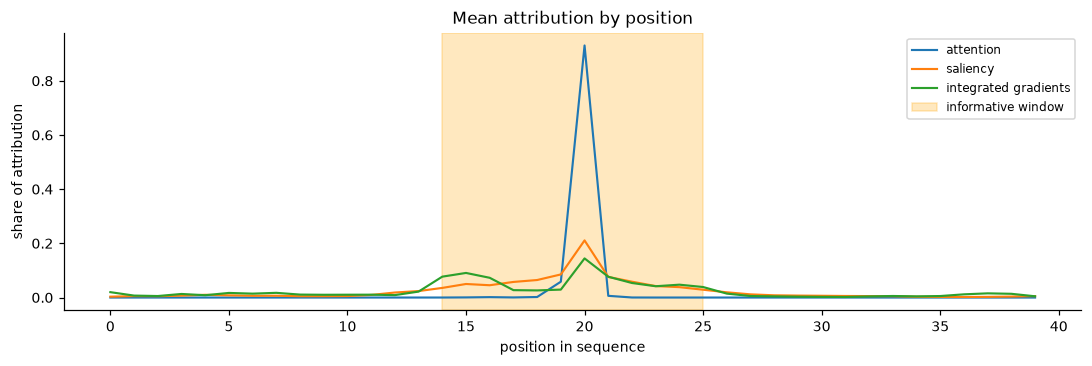

In [17]:
savefig(ca.plots.profile_comparison(
    {"attention": attn.mean(0), "saliency": sal.mean(0),
     "integrated gradients": ig.mean(0)}, highlight=WINDOW),
    "geno_attribution_comparison");

### Importance by event type

Grouping the attribution by event type rather than by genotype keeps the
heatmap readable, and asks a sharper question: do deletions and insertions
draw on different parts of the window? The generating rule says they should,
because their length signals sit on opposite sides of the cut.

,attribution in,deletion classes,insertion classes
0,deletion length block (14-16),0.265,0.2189
1,insertion length block (23-25),0.130,0.1671


deletion classes lean on their own length block by 2.04x
insertion classes lean on their own length block by 0.76x

The two event types do NOT separate onto their own length blocks.
The model is reaching the right answer without the division of labour
the generating rule implies, so the per class heatmap should not be
read as showing one.


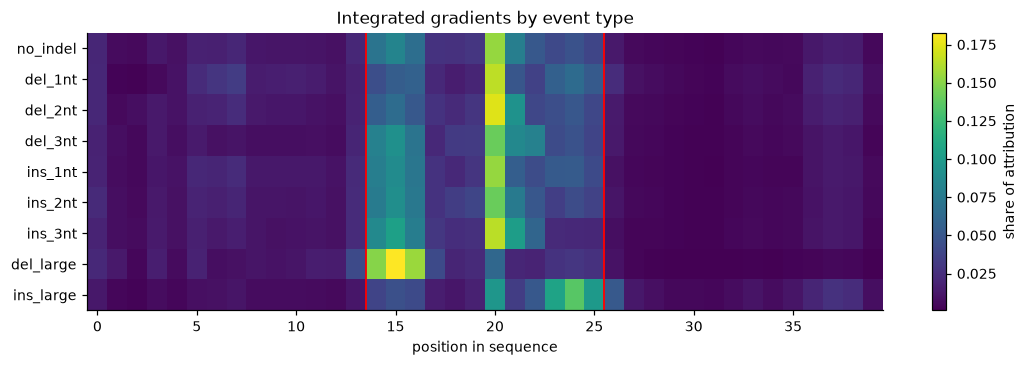

In [18]:
prof = ca.interpret.per_class_profile(ig, to_group[y[test]], len(GROUPS))
savefig(ca.plots.position_heatmap(prof, GROUPS, highlight=WINDOW,
                                  title="Integrated gradients by event type"),
        "geno_position_heatmap")

del_rows = [i for i, g in enumerate(GROUPS) if g.startswith("del")]
ins_rows = [i for i, g in enumerate(GROUPS) if g.startswith("ins")]
del_block = slice(cut - 2 * 3, cut - 3)   # sets deletion length
ins_block = slice(cut + 3, cut + 2 * 3)   # sets insertion length

tbl = pd.DataFrame({
    "attribution in": ["deletion length block "
                       f"({del_block.start}-{del_block.stop - 1})",
                       "insertion length block "
                       f"({ins_block.start}-{ins_block.stop - 1})"],
    "deletion classes": [round(float(prof[del_rows][:, del_block].sum(1).mean()), 4),
                         round(float(prof[del_rows][:, ins_block].sum(1).mean()), 4)],
    "insertion classes": [round(float(prof[ins_rows][:, del_block].sum(1).mean()), 4),
                          round(float(prof[ins_rows][:, ins_block].sum(1).mean()), 4)],
})
display(tbl)

d_own = prof[del_rows][:, del_block].sum(1).mean()
d_other = prof[del_rows][:, ins_block].sum(1).mean()
i_own = prof[ins_rows][:, ins_block].sum(1).mean()
i_other = prof[ins_rows][:, del_block].sum(1).mean()
print(f"deletion classes lean on their own length block by "
      f"{d_own / max(d_other, 1e-9):.2f}x")
print(f"insertion classes lean on their own length block by "
      f"{i_own / max(i_other, 1e-9):.2f}x")
print()
if d_own > d_other and i_own > i_other:
    print("Each event type draws more from the block that sets its own length,")
    print("which is what the generating rule put there.")
else:
    print("The two event types do NOT separate onto their own length blocks.")
    print("The model is reaching the right answer without the division of labour")
    print("the generating rule implies, so the per class heatmap should not be")
    print("read as showing one.")

## 11. Export and command line inference

In [19]:
ckpt = MODELS / "genotype_model.pt"
torch.save({
    "state_dict": model.state_dict(),
    "model_kwargs": dict(embed_dim=32, hidden_dim=96, attn_dim=96,
                         dropout=0.3, use_positional=True),
    "classes": CLASSES,
    "seq_length": int(X.shape[1]),
    "task": "genotype",
    "informative_window": list(WINDOW),
    "read_metrics": {k: float(res[k]) for k in
                     ("accuracy", "macro_f1", "weighted_f1", "balanced_accuracy")},
    "topk_accuracy": {str(k): float(v) for k, v in topk.items()},
    "majority_baseline_accuracy": float(res["baseline"]["accuracy"]),
    "group_ceiling_accuracy": float(ceiling),
    "site_metrics": {k: float(site[k]) for k in
                     ("modal_accuracy", "pooled_pearson_r", "mean_absolute_error")},
    "frequency_prior": {k: float(v) for k, v in prior.items()},
}, ckpt)
print(ckpt.name, f"{ckpt.stat().st_size / 1024:.0f} KB,", len(CLASSES), "classes")

genotype_model.pt 666 KB, 171 classes


In [20]:
example = EXAMPLES / "genotype_sequences.csv"
pick = np.random.default_rng(1).choice(test, 8, replace=False)
pd.DataFrame({"id": [f"site{groups[i]}_read{i}" for i in pick],
              "sequence": [ca.decode(X[i]) for i in pick],
              "true_genotype": [CLASSES[y[i]] for i in pick]}).to_csv(example, index=False)

run = subprocess.run([sys.executable, "predict.py",
                      "--model", f"models/{ckpt.name}",
                      "--input", f"examples/{example.name}",
                      "--id-col", "id",
                      "--output", "examples/genotype_predictions.csv"],
                     cwd=ROOT, capture_output=True, text=True)
print((run.stdout or run.stderr)[:600])

wrote 8 predictions to examples/genotype_predictions.csv
                id predicted_class  confidence  top_attended_position  p_no_indel  p_del_A  p_del_AA  p_del_AAA  p_del_AAC  p_del_AAG  p_del_AAT  p_del_AC  p_del_ACA  p_del_ACC  p_del_ACG  p_del_ACT  p_del_AG  p_del_AGA  p_del_AGC  p_del_AGG  p_del_AGT  p_del_AT  p_del_ATA  p_del_ATC  p_del_ATG  p_del_ATT  p_del_C  p_del_CA  p_del_CAA  p_del_CAC  p_del_CAG  p_del_CAT  p_del_CC  p_del_CCA  p_del_CCC  p_del_CCG  p_del_CCT  p_del_CG  p_del_CGA  p_del_CGC  p_del_CGG  p_del_CGT  p_del_CT  p_del_CTA  p_del_CTC  p_del_CTG  p_del_CTT  p_del_G  p


In [21]:
out = pd.read_csv(EXAMPLES / "genotype_predictions.csv")
truth = pd.read_csv(EXAMPLES / "genotype_sequences.csv")[["id", "true_genotype"]]
merged = out.merge(truth, on="id")
merged["top1_correct"] = merged.predicted_class == merged.true_genotype

# Top 1 is a hard bar with 171 classes, so show where the truth actually ranked.
prob_cols = [c for c in out.columns if c.startswith("p_")]
ranks = []
for _, row in merged.iterrows():
    ordered = row[prob_cols].astype(float).sort_values(ascending=False).index
    ranks.append(list(ordered).index("p_" + row.true_genotype) + 1)
merged["rank_of_truth"] = ranks
merged["in_top3"] = merged.rank_of_truth <= 3

display(merged[["id", "predicted_class", "confidence", "true_genotype",
                "top1_correct", "rank_of_truth", "in_top3"]])
print(f"top 1 correct in this sample: {merged.top1_correct.sum()}/{len(merged)}")
print(f"truth inside top 3          : {merged.in_top3.sum()}/{len(merged)}")
print("which is the sample level version of the top k table in section 6")
print("note: predict.py writes one probability column per class, so this "
      f"output has {len(CLASSES)} of them. Only the summary columns are shown.")

,id,predicted_class,confidence,true_genotype,top1_correct,rank_of_truth,in_top3
0,site4758_read47584,del_CAG,0.4593,no_indel,False,2,True
1,site2346_read23465,no_indel,0.5144,no_indel,True,1,True
2,site219_read2191,no_indel,0.4170,del_AC,False,2,True
3,site4754_read47544,del_CT,0.3761,no_indel,False,2,True
4,site3956_read39561,no_indel,0.3735,ins_TTA,False,3,True
5,site718_read7180,ins_large,0.5211,del_G,False,3,True
6,site3626_read36269,no_indel,0.3927,no_indel,True,1,True
7,site2479_read24795,del_CGG,0.4517,del_CGG,True,1,True


top 1 correct in this sample: 3/8
truth inside top 3          : 8/8
which is the sample level version of the top k table in section 6
note: predict.py writes one probability column per class, so this output has 171 of them. Only the summary columns are shown.


## 12. What this notebook shows

**Shown.**

- A genotype vocabulary of a few hundred classes with a long tail can be
  trained and evaluated end to end with the same architecture as the coarse
  tasks.
- The evaluation fits the task: top k accuracy, event type confusion, and site
  level distribution against a frequency prior.
- Section 8 is the honest test of whether sequence is being used, and it is
  reported either way.
- Class weighting, the standard answer to imbalance, **damages** this task.
  Section 9 measures it on an otherwise identical model.

**Not shown.**

- Nothing about repair biology. The rule was written by hand.
- Nothing about real genotype distributions. Real vocabularies are larger and
  more skewed, and include outcomes this benchmark does not generate.
- The large bins hide structure. `del_large` and `ins_large` each collapse
  many outcomes into one label. Lindel and FORECasT make the same compromise.